
# Driver Drowsiness Detection 

**Goal:** Build a binary Computer Vision model to classify driver faces as:

- `Non-Drowsy = 0`
- `Drowsy = 1`

Pipeline:

**Dataset → EDA → Face Detection → Augmentation → MobileNetV2 Transfer Learning → Fine-Tuning → Evaluation → Error Analysis → TFLite → Quantization → Download**

> Keep the supplied test set completely separate. Use only the training set for training and validation.


In [61]:

# 1. Install and import libraries

!pip install -q dlib

import os
import zipfile
import cv2
import dlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau,
    ModelCheckpoint
)

from google.colab import files

print("TensorFlow:", tf.__version__)

TensorFlow: 2.20.0



## 2. Optional: Download Dataset from Google Drive

Upload/extract the dataset into `/driver-drowsiness/dataset/`.

Expected structure:

```text
/driver-drowsiness/dataset/
├── train/
│   ├── Drowsy/
│   └── Non-Drowsy/
└── test/
    ├── Drowsy/
    └── Non-Drowsy/
```

If you have a ZIP file, upload it using the next cell.


In [62]:
import gdown

file_id = "1Z8VTDfzAgz67j6u3FKBmdpWG16xiESJB"

output = "/kaggle/working/driver-drowsiness.zip"

gdown.download(
    id=file_id,
    output=output,
    quiet=False
)

print("Downloaded:", output)

Downloading...
From (original): https://drive.google.com/uc?id=1Z8VTDfzAgz67j6u3FKBmdpWG16xiESJB
From (redirected): https://drive.google.com/uc?id=1Z8VTDfzAgz67j6u3FKBmdpWG16xiESJB&confirm=t&uuid=b2ce66fe-d03b-4960-a1d7-5818d46c34e7
To: /kaggle/working/driver-drowsiness.zip
100%|██████████| 667M/667M [00:01<00:00, 346MB/s]  


Downloaded: /kaggle/working/driver-drowsiness.zip


In [63]:
# Optional: extract uploaded ZIP files

for filename in os.listdir("/kaggle/working"):
    if filename.lower().endswith(".zip"):
        print("Extracting:", filename)
        with zipfile.ZipFile(
            os.path.join("/kaggle/working", filename), "r"
        ) as z:
            z.extractall("/kaggle/working/dataset")

print("Dataset extraction complete.")

Extracting: drowsiness_models.zip
Extracting: driver-drowsiness.zip
Dataset extraction complete.


In [64]:
import zipfile
import os

ZIP_PATH = "/kaggle/working/driver-drowsiness.zip"
EXTRACT_DIR = "/kaggle/working/driver-drowsiness"

os.makedirs(EXTRACT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction complete.")
print(os.listdir(EXTRACT_DIR))

Extraction complete.
['__MACOSX', 'dataset']


In [66]:
import os

DATASET_DIR = "/kaggle/working/driver-drowsiness/dataset"

print("Dataset contents:")
print(os.listdir(DATASET_DIR))


Dataset contents:
['test', '.DS_Store', 'train']


## 3. Dataset Configuration

In [67]:
TRAIN_DIR = os.path.join(DATASET_DIR, "train")
TEST_DIR = os.path.join(DATASET_DIR, "test")

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

# Explicit ordering is important:
CLASS_NAMES = ["non_drowsy", "drowsy"]

print("Train path:", TRAIN_DIR)
print("Test path :", TEST_DIR)

print("Train classes:", os.listdir(TRAIN_DIR))
print("Test classes :", os.listdir(TEST_DIR))

Train path: /kaggle/working/driver-drowsiness/dataset/train
Test path : /kaggle/working/driver-drowsiness/dataset/test
Train classes: ['drowsy', 'non_drowsy']
Test classes : ['drowsy', 'non_drowsy']


## 4. Dataset Inspection

In [68]:
def count_images(directory):
    counts = {}

    if not os.path.exists(directory):
        return counts

    for class_name in sorted(os.listdir(directory)):
        class_path = os.path.join(directory, class_name)

        if os.path.isdir(class_path):
            counts[class_name] = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])

    return counts


train_counts = count_images(TRAIN_DIR)
test_counts = count_images(TEST_DIR)

print("Train:", train_counts)
print("Test :", test_counts)


Train: {'drowsy': 3750, 'non_drowsy': 3750}
Test : {'drowsy': 1250, 'non_drowsy': 1250}


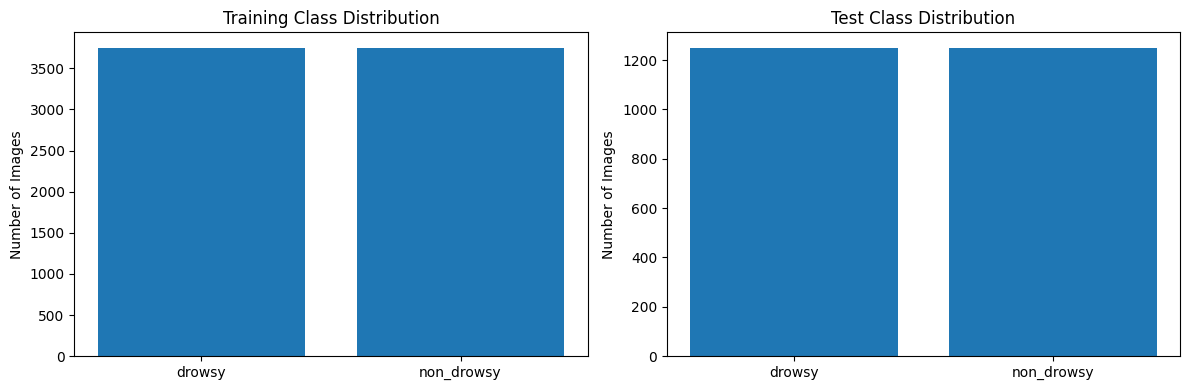

In [69]:
if train_counts:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].bar(train_counts.keys(), train_counts.values())
    axes[0].set_title("Training Class Distribution")
    axes[0].set_ylabel("Number of Images")

    axes[1].bar(test_counts.keys(), test_counts.values())
    axes[1].set_title("Test Class Distribution")
    axes[1].set_ylabel("Number of Images")

    plt.tight_layout()
    plt.show()


## 5. Visualize Samples

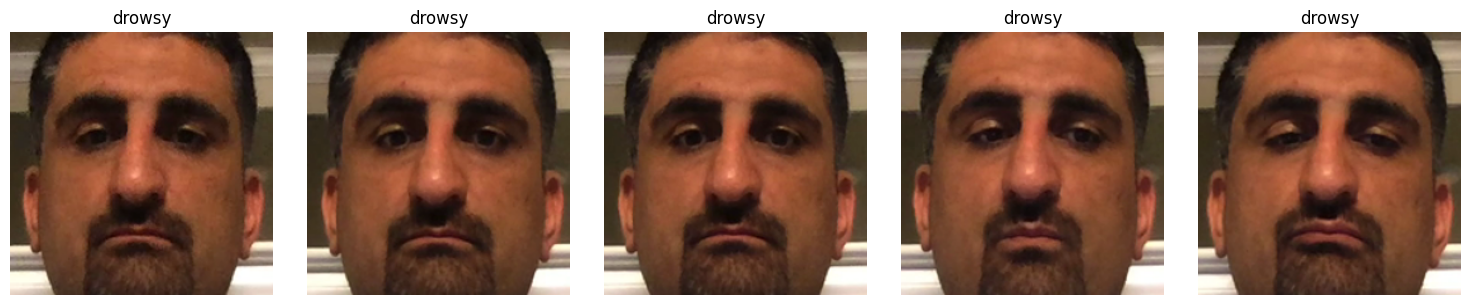

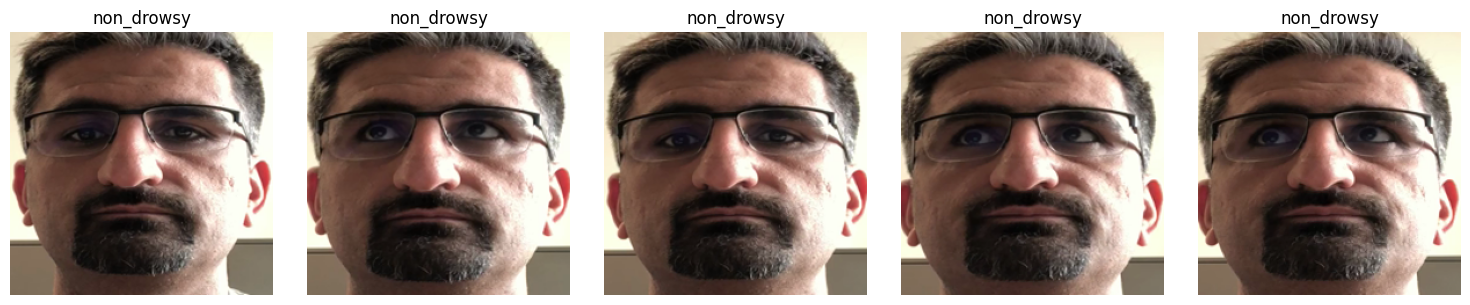

In [70]:
def display_samples(directory, class_name, n=5):
    class_dir = os.path.join(directory, class_name)

    if not os.path.isdir(class_dir):
        print("Folder not found:", class_dir)
        return

    image_files = [
        f for f in sorted(os.listdir(class_dir))
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ][:n]

    plt.figure(figsize=(15, 3))

    for i, filename in enumerate(image_files):
        image = cv2.imread(os.path.join(class_dir, filename))

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(1, len(image_files), i + 1)
        plt.imshow(image)
        plt.title(class_name)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

display_samples(TRAIN_DIR, "drowsy")
display_samples(TRAIN_DIR, "non_drowsy")



## 6. Dlib Face Detection

The supplied dataset already contains cropped faces, so Dlib is demonstrated as an additional face-isolation and quality-check step.


In [76]:
import cv2
import dlib
import numpy as np
import matplotlib.pyplot as plt

# Initialize Dlib HOG face detector
face_detector = dlib.get_frontal_face_detector()


def detect_and_crop_face(image, padding=0.15):

    if image is None:
        return None, None, "Invalid image"

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Detect faces
    faces = face_detector(gray, 1)

    if len(faces) == 0:
        return None, None, "No face detected"

    # Select largest face
    face = max(
        faces,
        key=lambda r: r.width() * r.height()
    )

    h, w = image.shape[:2]

    # Calculate bounding box
    x1, y1 = face.left(), face.top()
    x2, y2 = face.right(), face.bottom()

    # Add padding around face
    pad_x = int((x2 - x1) * padding)
    pad_y = int((y2 - y1) * padding)

    x1 = max(0, x1 - pad_x)
    y1 = max(0, y1 - pad_y)
    x2 = min(w, x2 + pad_x)
    y2 = min(h, y2 + pad_y)

    cropped_face = image[y1:y2, x1:x2]

    if cropped_face.size == 0:
        return None, None, "Invalid face crop"

    bbox = (x1, y1, x2, y2)

    return cropped_face, bbox, "Face detected"




In [77]:
def visualize_dlib_detection(image):

    cropped, bbox, status = detect_and_crop_face(image)

    display_image = image.copy()

    if bbox is not None:
        x1, y1, x2, y2 = bbox

        cv2.rectangle(
            display_image,
            (x1, y1),
            (x2, y2),
            (0, 255, 0),
            2
        )

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))

    axes[0].imshow(
        cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    )
    axes[0].set_title("Original Image")

    axes[1].imshow(
        cv2.cvtColor(display_image, cv2.COLOR_BGR2RGB)
    )
    axes[1].set_title("Dlib Face Detection")

    if cropped is not None:
        axes[2].imshow(
            cv2.cvtColor(cropped, cv2.COLOR_BGR2RGB)
        )
        axes[2].set_title("Cropped Face")
    else:
        axes[2].text(
            0.5, 0.5,
            status,
            ha="center",
            va="center"
        )
        axes[2].set_title("Detection Result")

    for ax in axes:
        ax.axis("off")

    plt.suptitle(status)
    plt.tight_layout()
    plt.show()

    return status

Image: /kaggle/working/driver-drowsiness/dataset/train/drowsy/ZC0606.png
Detection status: Face detected
Bounding box: (0, 9, 227, 227)


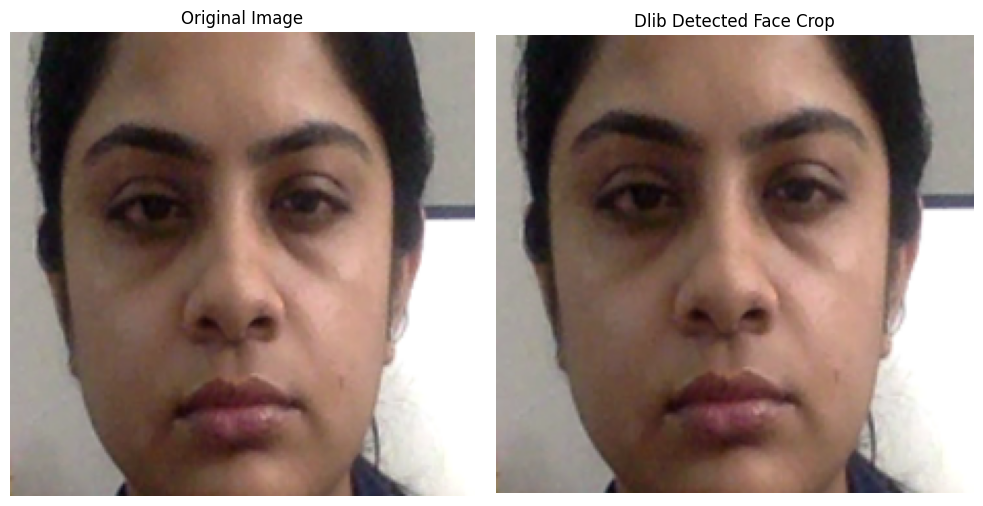

In [78]:
import os
import cv2
import matplotlib.pyplot as plt

# Automatically find one sample image
demo_path = None

for root, _, filenames in os.walk(TRAIN_DIR):
    for filename in filenames:
        if filename.lower().endswith((".jpg", ".jpeg", ".png")):
            demo_path = os.path.join(root, filename)
            break
    if demo_path:
        break

if demo_path:

    # Read original image
    original = cv2.imread(demo_path)

    if original is None:
        raise ValueError(f"Unable to load image: {demo_path}")

    # Detect and crop face
    cropped_face, bbox, status = detect_and_crop_face(original)

    print("Image:", demo_path)
    print("Detection status:", status)
    print("Bounding box:", bbox)

    # Create visualization
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))

    # Original image
    axes[0].imshow(
        cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
    )
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    # Cropped face
    if cropped_face is not None:

        axes[1].imshow(
            cv2.cvtColor(cropped_face, cv2.COLOR_BGR2RGB)
        )
        axes[1].set_title("Dlib Detected Face Crop")

    else:
        axes[1].text(
            0.5, 0.5,
            status,
            ha="center",
            va="center"
        )
        axes[1].set_title("Face Detection Failed")

    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

else:
    print("No sample image found.")


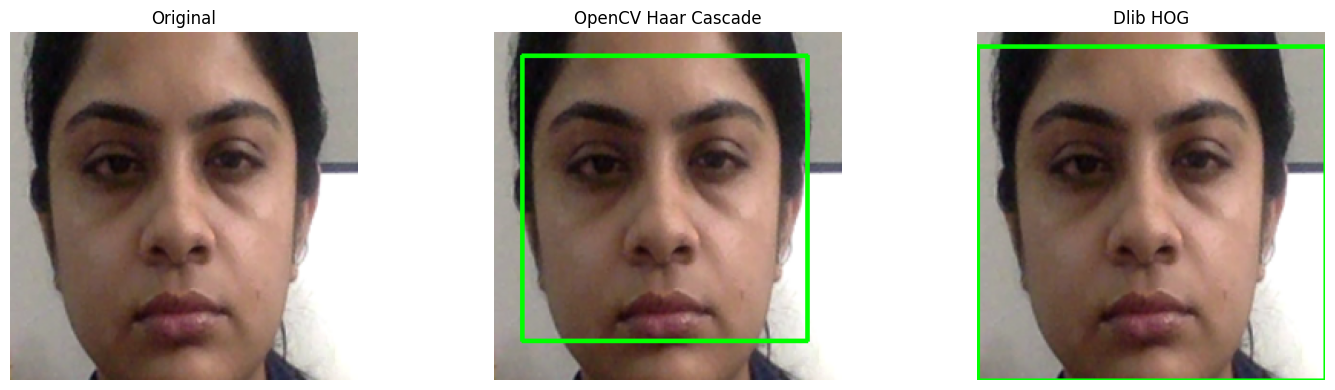

OpenCV detected: True
Dlib status: Face detected


In [79]:
# 7. OpenCV Haar Cascade Face Detection

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)


def detect_face_opencv(image):

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2GRAY
    )

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(30, 30)
    )

    output = image.copy()

    if len(faces) == 0:
        return output, None

    # Select largest detected face
    x, y, w, h = max(
        faces,
        key=lambda box: box[2] * box[3]
    )

    cv2.rectangle(
        output,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

    return output, (x, y, w, h)


# Compare OpenCV and Dlib on the same image

opencv_result, opencv_bbox = detect_face_opencv(original)

dlib_crop, dlib_bbox, dlib_status = detect_and_crop_face(original)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(
    cv2.cvtColor(original, cv2.COLOR_BGR2RGB)
)
axes[0].set_title("Original")

axes[1].imshow(
    cv2.cvtColor(opencv_result, cv2.COLOR_BGR2RGB)
)
axes[1].set_title("OpenCV Haar Cascade")

dlib_result = original.copy()

if dlib_bbox is not None:
    x1, y1, x2, y2 = dlib_bbox
    cv2.rectangle(
        dlib_result,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

axes[2].imshow(
    cv2.cvtColor(dlib_result, cv2.COLOR_BGR2RGB)
)
axes[2].set_title("Dlib HOG")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("OpenCV detected:", opencv_bbox is not None)
print("Dlib status:", dlib_status)

In [80]:
# 8. Batch Face Detection Quality Analysis

import os
import random
import pandas as pd

image_paths = []

for root, _, filenames in os.walk(TRAIN_DIR):
    for filename in filenames:
        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            image_paths.append(
                os.path.join(root, filename)
            )

# Reproducible sample
random.seed(42)
sample_paths = random.sample(
    image_paths,
    min(50, len(image_paths))
)

results = []

for path in sample_paths:

    image = cv2.imread(path)

    crop, bbox, status = detect_and_crop_face(image)

    results.append({
        "image": os.path.basename(path),
        "class": os.path.basename(os.path.dirname(path)),
        "face_detected": bbox is not None,
        "status": status
    })

results_df = pd.DataFrame(results)

print("Total images:", len(results_df))
print(
    "Successfully detected:",
    results_df["face_detected"].sum()
)
print(
    "Detection success rate:",
    round(
        results_df["face_detected"].mean() * 100,
        2
    ),
    "%"
)

print("\nDetection by class:")
print(
    results_df.groupby("class")[
        "face_detected"
    ].mean() * 100
)

display(results_df.head(10))

Total images: 50
Successfully detected: 49
Detection success rate: 98.0 %

Detection by class:
class
drowsy         96.428571
non_drowsy    100.000000
Name: face_detected, dtype: float64


,image,class,face_detected,status
0,zb0576.png,non_drowsy,True,Face detected
1,I0766.png,drowsy,True,Face detected
2,J0169.png,drowsy,True,Face detected
3,d0470.png,non_drowsy,True,Face detected
4,A0396.png,drowsy,True,Face detected
5,H0527.png,drowsy,True,Face detected
6,V0448.png,drowsy,True,Face detected
7,T0990.png,drowsy,True,Face detected
8,zc0405.png,non_drowsy,True,Face detected
9,X0134.png,drowsy,True,Face detected



## 7. Build Train / Validation / Test datasets

The test set is untouched until final evaluation.


In [38]:

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="training",
    seed=SEED,
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="validation",
    seed=SEED,
    shuffle=True
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="binary",
    class_names=CLASS_NAMES,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Classes:", train_ds.class_names)


Found 7500 files belonging to 2 classes.
Using 6000 files for training.
Found 7500 files belonging to 2 classes.
Using 1500 files for validation.
Found 2500 files belonging to 2 classes.
Classes: ['non_drowsy', 'drowsy']


## 8. Data Augmentation

In [39]:
class RandomBrightness(layers.Layer):
    def __init__(self, max_delta=0.15, **kwargs):
        super().__init__(**kwargs)
        self.max_delta = max_delta

    def call(self, inputs, training=None):
        if training:
            return tf.image.random_brightness(
                inputs,
                max_delta=self.max_delta * 255.0
            )
        return inputs


data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.10),
    layers.RandomTranslation(0.05, 0.05),
    layers.RandomContrast(0.15),
    RandomBrightness(0.15),
], name="data_augmentation")


In [55]:

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)



## 9. MobileNetV2 Transfer Learning

MobileNetV2 is pretrained on ImageNet. The base is initially frozen and a small binary classifier is trained on top.

`preprocess_input()` is used because standard MobileNetV2 preprocessing scales pixels to `[-1, 1]`.


In [56]:
base_model = MobileNetV2(
    input_shape=(128, 128, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(128, 128, 3))

x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.30)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = tf.keras.Model(inputs, outputs)

model.summary()


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide_2 (TrueDivide)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract_2 (Subtract)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 10. Phase 1 — Frozen Base Training

In [57]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

callbacks_phase1 = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-7
    ),
    ModelCheckpoint(
        "best_phase1.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_phase1
)


Epoch 1/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 14s 50ms/step - accuracy: 0.7003 - loss: 0.5710 - precision: 0.7005 - recall: 0.6996 - val_accuracy: 0.8007 - val_loss: 0.4380 - val_precision: 0.7790 - val_recall: 0.8402 - learning_rate: 0.0010
Epoch 2/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.8273 - loss: 0.3979 - precision: 0.8221 - recall: 0.8353 - val_accuracy: 0.8913 - val_loss: 0.3404 - val_precision: 0.9311 - val_recall: 0.8455 - learning_rate: 0.0010
Epoch 3/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.8718 - loss: 0.3349 - precision: 0.8680 - recall: 0.8770 - val_accuracy: 0.9153 - val_loss: 0.2843 - val_precision: 0.9127 - val_recall: 0.9188 - learning_rate: 0.0010
Epoch 4/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accuracy: 0.8858 - loss: 0.2987 - precision: 0.8854 - recall: 0.8863 - val_accuracy: 0.9240 - val_loss: 0.2530 - val_precision: 0.9310 - val_recall: 0.9161 - learning_rate: 0.0010
Epoch 5/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 7s 38ms/step - accu

## 11. Phase 2 — Fine-Tuning

In [58]:

base_model.trainable = True

# Fine-tune only the later part of MobileNetV2.
fine_tune_at = 100

for layer in base_model.layers[:fine_tune_at]:
    layer.trainable = False

# Keep BatchNormalization layers frozen for stable fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

callbacks_phase2 = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=2,
        min_lr=1e-8
    ),
    ModelCheckpoint(
        "best_final.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_phase2
)

Epoch 1/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 18s 58ms/step - accuracy: 0.9460 - loss: 0.1415 - precision: 0.9463 - recall: 0.9456 - val_accuracy: 0.9733 - val_loss: 0.0791 - val_precision: 0.9684 - val_recall: 0.9787 - learning_rate: 1.0000e-05
Epoch 2/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step - accuracy: 0.9747 - loss: 0.0736 - precision: 0.9731 - recall: 0.9763 - val_accuracy: 0.9847 - val_loss: 0.0481 - val_precision: 0.9777 - val_recall: 0.9920 - learning_rate: 1.0000e-05
Epoch 3/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step - accuracy: 0.9777 - loss: 0.0568 - precision: 0.9751 - recall: 0.9803 - val_accuracy: 0.9907 - val_loss: 0.0371 - val_precision: 0.9973 - val_recall: 0.9840 - learning_rate: 1.0000e-05
Epoch 4/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 49ms/step - accuracy: 0.9882 - loss: 0.0350 - precision: 0.9877 - recall: 0.9887 - val_accuracy: 0.9887 - val_loss: 0.0355 - val_precision: 0.9986 - val_recall: 0.9787 - learning_rate: 1.0000e-05
Epoch 5/15
188/188 ━━━━━━━━━━━━━━━━━━━━ 9s 

## 12. Training Curves

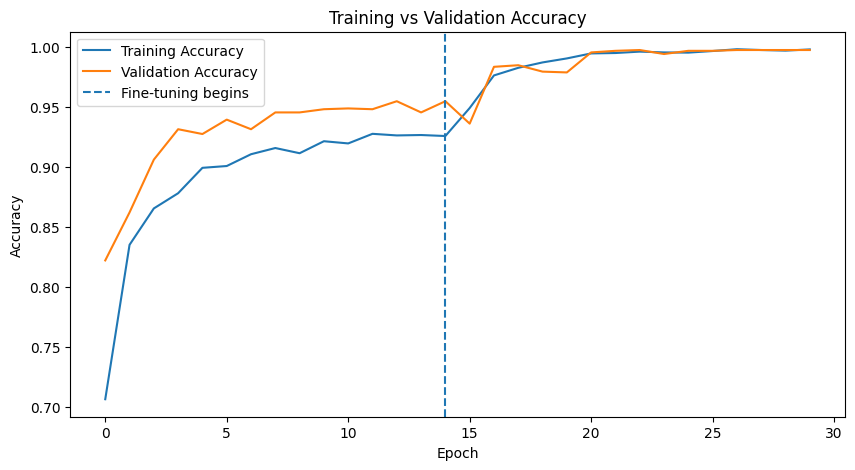

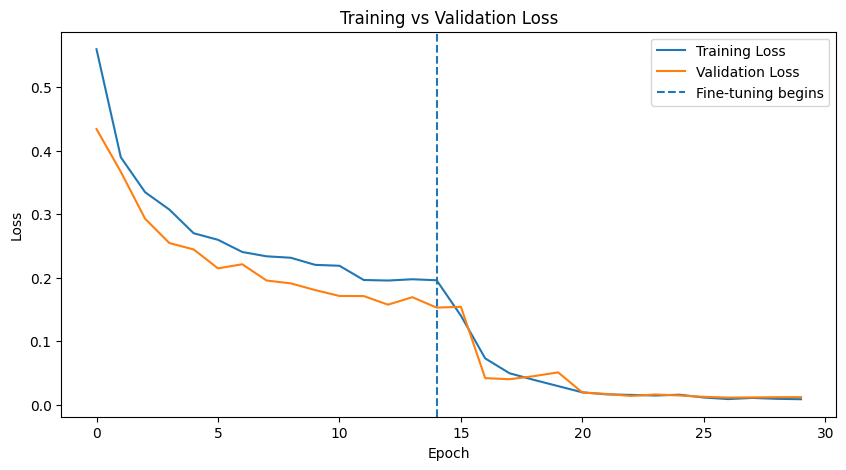

In [46]:
def combine_history(h1, h2, metric):
    values = h1.history[metric] + h2.history[metric]
    val_values = (
        h1.history[f"val_{metric}"] +
        h2.history[f"val_{metric}"]
    )
    return values, val_values

acc, val_acc = combine_history(history1, history2, "accuracy")
loss, val_loss = combine_history(history1, history2, "loss")

plt.figure(figsize=(10, 5))
plt.plot(acc, label="Training Accuracy")
plt.plot(val_acc, label="Validation Accuracy")
plt.axvline(
    len(history1.history["accuracy"]) - 1,
    linestyle="--",
    label="Fine-tuning begins"
)
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(loss, label="Training Loss")
plt.plot(val_loss, label="Validation Loss")
plt.axvline(
    len(history1.history["loss"]) - 1,
    linestyle="--",
    label="Fine-tuning begins"
)
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()


## 13. Final Test Evaluation

In [47]:
y_true = []
y_prob = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0).ravel()
    y_prob.extend(predictions)
    y_true.extend(labels.numpy().ravel())

y_true = np.array(y_true).astype(int)
y_prob = np.array(y_prob)

threshold = 0.50
y_pred = (y_prob >= threshold).astype(int)

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
recall = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Drowsy Recall: {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Non-Drowsy", "Drowsy"],
        zero_division=0
    )
)

Accuracy : 0.9980
Precision: 0.9968
Drowsy Recall: 0.9992
F1 Score : 0.9980

Classification Report:
              precision    recall  f1-score   support

  Non-Drowsy       1.00      1.00      1.00      1250
      Drowsy       1.00      1.00      1.00      1250

    accuracy                           1.00      2500
   macro avg       1.00      1.00      1.00      2500
weighted avg       1.00      1.00      1.00      2500



## 14. Confusion Matrix

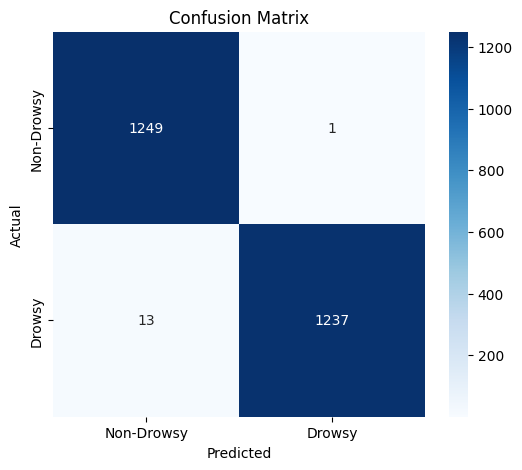

Important safety error: False Negative = actual Drowsy, predicted Non-Drowsy.


In [20]:

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Drowsy", "Drowsy"],
    yticklabels=["Non-Drowsy", "Drowsy"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

print("Important safety error: False Negative = actual Drowsy, predicted Non-Drowsy.")


## 15. Threshold Optimization

,threshold,precision,recall,f1
0,0.10,0.986582,1.0000,0.993246
1,0.15,0.990491,1.0000,0.995223
2,0.20,0.991277,1.0000,0.995619
3,0.25,0.994431,1.0000,0.997208
4,0.30,0.994431,1.0000,0.997208
5,0.35,0.996013,0.9992,0.997604
6,0.40,0.996013,0.9992,0.997604
7,0.45,0.996013,0.9992,0.997604
8,0.50,0.996808,0.9992,0.998002
9,0.55,0.997604,0.9992,0.998401


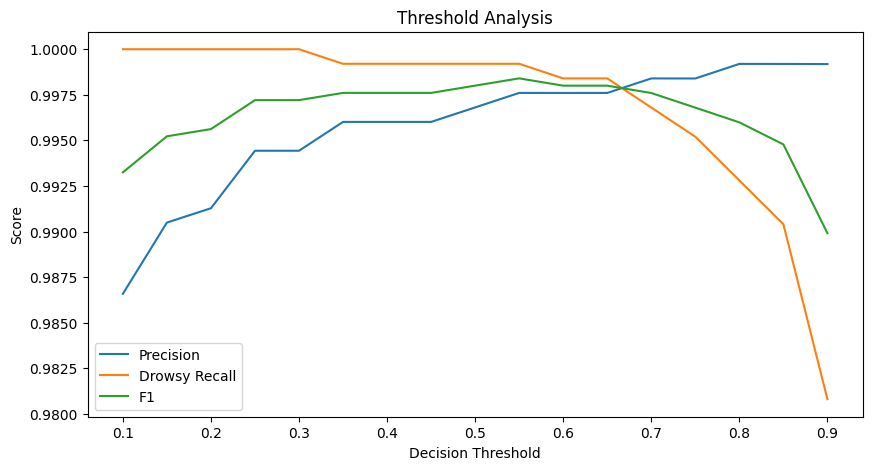

In [48]:

thresholds = np.arange(0.10, 0.91, 0.05)

results = []

for t in thresholds:
    predictions = (y_prob >= t).astype(int)

    results.append({
        "threshold": round(float(t), 2),
        "precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_true, predictions, zero_division=0
        )
    })

threshold_df = pd.DataFrame(results)
display(threshold_df)

plt.figure(figsize=(10, 5))
plt.plot(threshold_df["threshold"], threshold_df["precision"], label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], label="Drowsy Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="F1")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Threshold Analysis")
plt.legend()
plt.show()


## 16. False-Negative Analysis

Number of missed Drowsy cases: 1


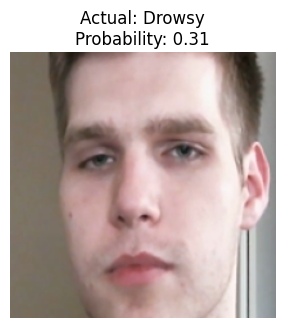

In [49]:
false_negative_indices = np.where(
    (y_true == 1) & (y_pred == 0)
)[0]

print("Number of missed Drowsy cases:", len(false_negative_indices))

# Build an ordered list of test image paths matching image_dataset_from_directory.
def collect_test_images(directory):
    records = []

    for class_name in CLASS_NAMES:
        class_dir = os.path.join(directory, class_name)

        if not os.path.isdir(class_dir):
            continue

        for filename in sorted(os.listdir(class_dir)):
            if filename.lower().endswith((".jpg", ".jpeg", ".png")):
                records.append({
                    "path": os.path.join(class_dir, filename),
                    "class_name": class_name
                })

    return records


test_records = collect_test_images(TEST_DIR)

if len(test_records) == len(y_true) and len(false_negative_indices) > 0:
    selected = false_negative_indices[:12]

    plt.figure(figsize=(15, 9))

    for i, idx in enumerate(selected):
        image = cv2.imread(test_records[idx]["path"])

        if image is None:
            continue

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        plt.subplot(3, 4, i + 1)
        plt.imshow(image)
        plt.title(f"Actual: Drowsy\nProbability: {y_prob[idx]:.2f}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("Could not align test files automatically for visualization.")


## 17. TFLite Float32 Conversion

In [50]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_float32 = converter.convert()

with open("drowsiness_mobilenetv2_float32.tflite", "wb") as f:
    f.write(tflite_float32)

size_mb = os.path.getsize("drowsiness_mobilenetv2_float32.tflite") / (1024 * 1024)
print(f"Float32 TFLite size: {size_mb:.2f} MB")

INFO:tensorflow:Assets written to: /tmp/tmpldnnh295/assets


INFO:tensorflow:Assets written to: /tmp/tmpldnnh295/assets


Saved artifact at '/tmp/tmpldnnh295'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_323')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139424707170704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139424866402128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306371536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306371728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306374032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1394223063

W0000 00:00:1793914604.822826      58 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793914604.822892      58 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


## 18. TFLite Float16 Quantization

In [51]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_types = [tf.float16]

tflite_float16 = converter.convert()

with open("drowsiness_mobilenetv2_float16.tflite", "wb") as f:
    f.write(tflite_float16)

size_mb = os.path.getsize("drowsiness_mobilenetv2_float16.tflite") / (1024 * 1024)
print(f"Float16 TFLite size: {size_mb:.2f} MB")

INFO:tensorflow:Assets written to: /tmp/tmppsuemfhi/assets


INFO:tensorflow:Assets written to: /tmp/tmppsuemfhi/assets


Saved artifact at '/tmp/tmppsuemfhi'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_323')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139424707170704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139424866402128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306371536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306371728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306374032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1394223063

W0000 00:00:1793914614.182788      58 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793914614.182841      58 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


## 19. TFLite INT8 Quantization

In [52]:

# Representative dataset for calibration.
# Note: data is fed through the model's own preprocessing pipeline.

def representative_dataset():
    for images, _ in train_ds.take(100):
        for image in images:
            yield [tf.expand_dims(tf.cast(image, tf.float32), axis=0)]


converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.representative_dataset = representative_dataset

tflite_int8 = converter.convert()

with open("drowsiness_mobilenetv2_int8.tflite", "wb") as f:
    f.write(tflite_int8)

size_mb = os.path.getsize("drowsiness_mobilenetv2_int8.tflite") / (1024 * 1024)
print(f"INT8 TFLite size: {size_mb:.2f} MB")


INFO:tensorflow:Assets written to: /tmp/tmptc_1c8wn/assets


INFO:tensorflow:Assets written to: /tmp/tmptc_1c8wn/assets


Saved artifact at '/tmp/tmptc_1c8wn'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_323')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  139424707170704: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372304: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139424866402128: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306371536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372688: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306372880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306371728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139422306374032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1394223063

/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/convert.py:863: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(
W0000 00:00:1793914624.136447      58 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1793914624.136497      58 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.


INT8 TFLite size: 2.59 MB


fully_quantize: 0, inference_type: 6, input_inference_type: FLOAT32, output_inference_type: FLOAT32


## 20. TFLite Inference Demonstration

In [53]:
interpreter = tf.lite.Interpreter( model_path="drowsiness_mobilenetv2_float16.tflite")

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Input details:", input_details)
print("Output details:", output_details)


Input details: [{'name': 'serving_default_keras_tensor_323:0', 'index': 0, 'shape': array([  1, 128, 128,   3], dtype=int32), 'shape_signature': array([ -1, 128, 128,   3], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]
Output details: [{'name': 'StatefulPartitionedCall_1:0', 'index': 284, 'shape': array([1, 1], dtype=int32), 'shape_signature': array([-1,  1], dtype=int32), 'dtype': <class 'numpy.float32'>, 'quantization': (0.0, 0), 'quantization_parameters': {'scales': array([], dtype=float32), 'zero_points': array([], dtype=int32), 'quantized_dimension': 0}, 'sparsity_parameters': {}}]


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


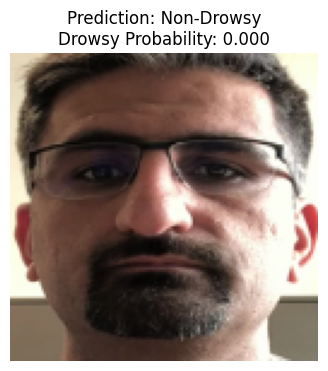

In [54]:

images, labels = next(iter(test_ds))

sample = images[0:1].numpy().astype(np.float32)

interpreter.set_tensor(
    input_details[0]["index"],
    sample
)

interpreter.invoke()

prediction = interpreter.get_tensor(
    output_details[0]["index"]
)

probability = float(prediction[0][0])
predicted_class = "Drowsy" if probability >= 0.50 else "Non-Drowsy"

plt.figure(figsize=(4, 4))
plt.imshow(images[0].numpy().astype("uint8"))
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Drowsy Probability: {probability:.3f}"
)
plt.axis("off")
plt.show()


## 21. Model Size Comparison

In [28]:

# Save best Keras model if it exists in memory.
model.save("drowsiness_model.keras")

model_files = [
    "drowsiness_model.keras",
    "drowsiness_mobilenetv2_float32.tflite",
    "drowsiness_mobilenetv2_float16.tflite",
    "drowsiness_mobilenetv2_int8.tflite"
]

rows = []

for filename in model_files:
    if os.path.exists(filename):
        rows.append({
            "Model": filename,
            "Size_MB": round(
                os.path.getsize(filename) / (1024 * 1024),
                4
            )
        })

size_df = pd.DataFrame(rows)
display(size_df)


,Model,Size_MB
0,drowsiness_model.keras,23.2553
1,drowsiness_mobilenetv2_float32.tflite,8.4593
2,drowsiness_mobilenetv2_float16.tflite,4.2594
3,drowsiness_mobilenetv2_int8.tflite,2.5861



# 22. Business Questions

### 1. Why not start from scratch?
The dataset is relatively small. Training a deep CNN from random initialization can overfit and requires more data and compute. Transfer learning with ImageNet-pretrained MobileNetV2 reuses useful visual features and adapts them to the drowsiness task.

### 2. Which mistake is more dangerous?
Missing a genuinely drowsy driver is more dangerous than generating a false alarm. Therefore, **Drowsy Recall** is a key metric. Precision still matters because too many false alarms can reduce driver trust.

### 3. How do we handle changing lighting?
Use realistic augmentation such as brightness, contrast, rotation, zoom, translation and horizontal flipping. Also inspect performance on low-light and shadowed images.

### 4. Why detect the face first?
Face detection focuses the model on relevant signals such as eye closure, mouth opening and head posture while reducing irrelevant dashboard/background information. Poor face detection can itself create bad inputs, so detection failures must be monitored.

### 5. How do we shrink the model?
Use MobileNetV2, convert it to TensorFlow Lite and apply Float16 or INT8 quantization. The trade-off is that lower precision can introduce some accuracy loss.

### 6. Why train in two phases?
First train the new classification head with the pretrained base frozen. Then fine-tune selected upper layers using a much smaller learning rate. This preserves useful pretrained representations and reduces the risk of damaging them.

### 7. Is 95% accuracy enough?
No. Accuracy can hide poor Drowsy detection, particularly with imbalanced classes. Precision, Recall, F1-score and the confusion matrix are necessary. For this safety problem, Drowsy Recall deserves special attention.

### 8. How can the model be improved?
First, inspect false negatives and add/augment data for the observed failure modes. Second, tune the decision threshold on validation data to improve Drowsy recall while keeping false alarms manageable.

### 9. Actionable business recommendation
The classifier should be part of a complete alerting pipeline:

**Camera → Face Detection → Drowsiness Model → Temporal Smoothing → Warning → Escalation**

Using several consecutive frames can reduce alerts caused by a single blink or noisy prediction.



# 23. Download Functions for Google Colab

Run the next cell after training/conversion. It creates one ZIP containing the trained Keras model and all TFLite models.


In [29]:

def download_file(filename):
    """Download one existing file from the Colab runtime."""
    if not os.path.exists(filename):
        raise FileNotFoundError(f"File not found: {filename}")

    files.download(filename)


def download_keras_model(filename="drowsiness_model.keras"):
    """Save current model and download it."""
    model.save(filename)
    files.download(filename)


def create_model_zip(output_zip="drowsiness_models.zip"):
    """Package all available trained models into one ZIP."""

    model_files = [
        "drowsiness_model.keras",
        "drowsiness_mobilenetv2_float32.tflite",
        "drowsiness_mobilenetv2_float16.tflite",
        "drowsiness_mobilenetv2_int8.tflite"
    ]

    existing_files = [
        filename for filename in model_files
        if os.path.exists(filename)
    ]

    if not existing_files:
        raise FileNotFoundError(
            "No model files found. Run training and TFLite conversion first."
        )

    with zipfile.ZipFile(
        output_zip,
        "w",
        zipfile.ZIP_DEFLATED
    ) as zipf:

        for filename in existing_files:
            zipf.write(filename)

    print("Created:", output_zip)
    print("Included:")
    for filename in existing_files:
        print(" -", filename)

    return output_zip

## 24. One-Click Download — All Models

In [30]:
# This is the main download cell.
# Run it after the model has been trained and TFLite files have been created.

model.save("drowsiness_model.keras")

zip_file = create_model_zip("drowsiness_models.zip")

files.download(zip_file)

Created: drowsiness_models.zip
Included:
 - drowsiness_model.keras
 - drowsiness_mobilenetv2_float32.tflite
 - drowsiness_mobilenetv2_float16.tflite
 - drowsiness_mobilenetv2_int8.tflite


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


# 25. Submission Checklist

- [ ] Dataset distribution shown
- [ ] Sample images shown
- [ ] Face detection demonstrated
- [ ] Data augmentation implemented
- [ ] MobileNetV2 transfer learning implemented
- [ ] Phase 1 training completed
- [ ] Phase 2 fine-tuning completed
- [ ] Training curves shown
- [ ] Accuracy, Precision, Recall and F1 reported
- [ ] Confusion matrix shown
- [ ] False-negative analysis completed
- [ ] Threshold analysis completed
- [ ] TFLite Float32 created
- [ ] TFLite Float16 created
- [ ] TFLite INT8 created
- [ ] TFLite inference demonstrated
- [ ] Model sizes compared
- [ ] Business questions answered in markdown
- [ ] Test set kept separate
- [ ] Colab notebook exported as PDF using **File → Print → Save as PDF**
